# 09 · Tune visual document retrieval

An accounts-payable analyst remembers a supplier and displayed balance, or the
date and a service line. Retrieve the one matching page from a fixed candidate
pool. Compare OCR BM25, a frozen image retriever and a learned query projection.
The projection changes scores against an index built once.

## 1. Choose a bounded profile

Start with the default T4 profile. The full profile raises the page and step
counts. Both profiles preserve the source fixtures, model revision and comparison.

In [1]:
import os
import shutil
import subprocess
import sys

import torch

if not torch.cuda.is_available() or "T4" not in torch.cuda.get_device_name():
    raise RuntimeError("Select a Colab T4 for this notebook.")
if not shutil.which("tesseract"):
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(["apt-get", "install", "-y", "-qq", "tesseract-ocr"], check=True)
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "transformers==4.57.1",
     "rank-bm25==0.2.2", "pytesseract==0.3.13"],
    check=True,
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'transformers==4.57.1', 'rank-bm25==0.2.2', 'pytesseract==0.3.13'], returncode=0)

In [2]:
"""Versioned synthetic invoices and independent record scoring for the course."""

from __future__ import annotations

import json
import random
import re
from collections import Counter
from dataclasses import dataclass
from datetime import date, timedelta
from typing import Any

CATALOG_VERSION = "course-invoice-v1"
SPLIT_SIZES = {"train": 576, "dev": 72, "familiar": 96, "novel": 96, "independent": 48, "release": 120}
VISIBLE_CONTRACT = (
    "Extract exactly one JSON object with invoice_id, issued_on (YYYY-MM-DD), supplier, "
    "currency (ISO code), line_items (description, quantity, unit_minor), subtotal_minor, "
    "tax_minor, and total_minor. Preserve line order and convert currency amounts to integer cents. "
    "Use null only for a missing or ambiguous field. Do not rewrite printed amounts, invent fields, or add explanations."
)

@dataclass(frozen=True)
class Line:
    description: str
    quantity: int
    unit_minor: int


@dataclass(frozen=True)
class Invoice:
    key: str
    family: str
    supplier: str
    issued_on: str
    currency: str
    items: tuple[Line, ...]
    tax_minor: int | None
    locale: str
    split: str
    layout: str = "register"
    printed_total_minor: int | None = None


def invoice_record(invoice: Invoice) -> dict[str, Any]:
    subtotal = sum(line.quantity * line.unit_minor for line in invoice.items)
    total = subtotal + invoice.tax_minor if invoice.tax_minor is not None else None
    if invoice.printed_total_minor is not None:
        total = invoice.printed_total_minor
    return {
        "invoice_id": invoice.key,
        "issued_on": invoice.issued_on,
        "supplier": invoice.supplier,
        "currency": invoice.currency,
        "line_items": [
            {"description": item.description, "quantity": item.quantity, "unit_minor": item.unit_minor}
            for item in invoice.items
        ],
        "subtotal_minor": subtotal,
        "tax_minor": invoice.tax_minor,
        "total_minor": total,
    }


def make_catalog() -> list[Invoice]:
    rng = random.Random(20261126)
    sources = {
        "train": (24, ("register", "memo", "checkout", "ledger")),
        "dev": (6, ("register", "memo", "checkout", "ledger")),
        "familiar": (8, ("register", "memo", "checkout", "ledger")),
        "novel": (8, ("packing", "remittance", "service", "notice")),
        "independent": (4, ("separate",)),
        "release": (10, ("packing", "remittance", "service", "notice", "separate")),
    }
    locales = (("en-US", "USD"), ("en-GB", "GBP"), ("de-DE", "EUR"), ("fr-FR", "EUR"), ("en-US", "CAD"))
    services = ("Cooling filter", "Cable sleeve", "Bench calibration", "Door seal", "Grounding clip",
                "Rack inspection", "Meter label", "Packing insert", "Carrier adjustment", "Mounting plate")
    catalog = []
    seen_keys = set()
    supplier_codes = rng.sample(range(1000, 9999), sum(n for n, _ in sources.values()))
    supplier_index = 0
    for split, (family_count, layouts) in sources.items():
        for family_number in range(family_count):
            supplier_code = supplier_codes[supplier_index]
            supplier_index += 1
            layout = layouts[family_number % len(layouts)]
            family = f"{split}-{family_number:02d}"
            locale, currency = locales[family_number % len(locales)]
            for row in range(SPLIT_SIZES[split] // family_count):
                code = f"SF-{rng.randrange(100000, 1000000)}"
                while code in seen_keys:
                    code = f"SF-{rng.randrange(100000, 1000000)}"
                seen_keys.add(code)
                items = tuple(
                    Line(kind, rng.randint(1, 9), rng.randrange(200, 24800))
                    for kind in rng.sample(services, rng.randrange(1, 4))
                )
                subtotal = sum(x.quantity * x.unit_minor for x in items)
                tax = (subtotal * (7 if currency == "USD" else 13) + 50) // 100
                if split in {"novel", "independent", "release"} and row % 12 == 4:
                    tax = None
                displayed = subtotal + tax + 101 if tax is not None and row % 12 == 7 else None
                issued_on = (date(2025, 1, 1) + timedelta(days=rng.randint(0, 590))).isoformat()
                catalog.append(Invoice(code, family, f"Sample Supplier {supplier_code}", issued_on,
                                       currency, items, tax, locale, split, layout, displayed))
    return catalog


def formatted_money(minor: int | None, locale: str) -> str:
    if minor is None:
        return "-"
    dollars, cents = divmod(minor, 100)
    number = f"{dollars:,}.{cents:02d}"
    if locale == "de-DE":
        return number.replace(",", "_").replace(".", ",").replace("_", ".")
    if locale == "fr-FR":
        return number.replace(",", " ").replace(".", ",")
    return number


def invoice_text(invoice: Invoice) -> str:
    gold = invoice_record(invoice)
    money = lambda value: formatted_money(value, invoice.locale)
    identifier = f"{invoice.key}"
    supplier = invoice.supplier
    issued = invoice.issued_on
    currency = invoice.currency
    subtotal = money(gold["subtotal_minor"])
    tax = money(gold["tax_minor"])
    total = money(gold["total_minor"])
    register = [f"{row.description} | {row.quantity} | {money(row.unit_minor)}" for row in invoice.items]
    inline = [f"{row.quantity} x {row.description} @ {money(row.unit_minor)} per unit" for row in invoice.items]
    service = [f"{row.description}: {money(row.unit_minor)} each for {row.quantity} units" for row in invoice.items]
    if invoice.layout == "register":
        return "\n".join([f"Supplier: {supplier}", f"Invoice: {identifier}", f"Issued: {issued}", f"Currency: {currency}",
                          "Description | Quantity | Unit price", *register,
                          f"Subtotal: {subtotal}", f"Tax: {tax}", f"Amount due: {total}"])
    if invoice.layout == "memo":
        return "\n".join([f"{supplier} billing memo / {issued}", f"Account invoice {identifier} [{currency}]",
                          *inline, f"Total due {total} including tax {tax}; net amount {subtotal}."])
    if invoice.layout == "checkout":
        return "\n".join([f"{identifier} / supplier {supplier}", f"Date of issue {issued} / All amounts {currency}",
                          *service, f"Net {subtotal}", f"Sales tax {tax}", f"Payable {total}"])
    if invoice.layout == "ledger":
        return "\n".join([f"{supplier} | issued {issued} | invoice {identifier}", f"Ledger in {currency}",
                          "Service | Count | Per unit", *register, f"Before tax {subtotal}",
                          f"Tax charged {tax}", f"Balance {total}"])
    if invoice.layout == "packing":
        return "\n".join([f"Billing details / {identifier}", f"Sold by {supplier}", f"Document date {issued}",
                          f"Invoice currency {currency}", f"Balance payable {total}", *service,
                          f"Merchandise {subtotal}", f"Tax {tax}"])
    if invoice.layout == "remittance":
        return "\n".join([f"Remittance advice for {identifier} ({currency})", f"{supplier} / Document issued {issued}",
                          f"Pay this amount {total}", *inline, f"Net charges {subtotal} / Tax {tax}"])
    if invoice.layout == "service":
        return "\n".join([f"Ref {identifier} / {currency}", f"Service fee notice, {issued}", supplier,
                          *[f"Unit {money(row.unit_minor)} / {row.quantity} times / {row.description}" for row in invoice.items],
                          f"Fee subtotal {subtotal}", f"Plus tax {tax}", f"Amount requested {total}"])
    if invoice.layout == "notice":
        return "\n".join([f"{supplier} / statement {identifier}", f"Issued on {issued}",
                          f"Invoice denomination {currency}", "One-off charges", *service,
                          f"Pre-tax {subtotal} / Tax assessment {tax} / Final bill {total}"])
    return "\n".join([f"Document {identifier}", f"Biller {supplier} / As of {issued} / {currency}", *inline,
                      f"Gross {total}", f"Breakdown: net {subtotal} and taxes {tax}."])


def _strict_dict(pairs: list[tuple[str, Any]]) -> dict[str, Any]:
    result: dict[str, Any] = {}
    for key, value in pairs:
        if key in result:
            raise ValueError(f"Duplicate JSON key {key!r}")
        result[key] = value
    return result


def parse_record(completion: str | dict[str, Any]) -> dict[str, Any] | None:
    if isinstance(completion, str):
        try:
            data = json.loads(completion, object_pairs_hook=_strict_dict)
        except (ValueError, TypeError, RecursionError):
            return None
    else:
        data = completion
    keys = {"invoice_id", "issued_on", "supplier", "currency", "line_items", "subtotal_minor", "tax_minor", "total_minor"}
    if not isinstance(data, dict) or set(data) != keys:
        return None
    for name in ("invoice_id", "supplier", "issued_on", "currency"):
        value = data[name]
        if value is not None and (not isinstance(value, str) or not value.strip()):
            return None
    try:
        if data["issued_on"] is not None and date.fromisoformat(data["issued_on"]).isoformat() != data["issued_on"]:
            return None
    except ValueError:
        return None
    if data["currency"] is not None and re.fullmatch("[A-Z]{3}", data["currency"]) is None:
        return None
    for name in ("subtotal_minor", "tax_minor", "total_minor"):
        if data[name] is not None and type(data[name]) is not int:
            return None
    if not isinstance(data["line_items"], list):
        return None
    for row in data["line_items"]:
        if not isinstance(row, dict) or set(row) != {"description", "quantity", "unit_minor"}:
            return None
        if type(row["description"]) is not str or type(row["quantity"]) is not int or type(row["unit_minor"]) is not int:
            return None
        if not row["description"].strip() or row["quantity"] <= 0:
            return None
    return data


def score_record(completion: str | dict[str, Any], invoice: Invoice) -> dict[str, Any]:
    truth = invoice_record(invoice)
    observed = parse_record(completion)
    field_correct = {key: observed is not None and observed.get(key) == value
                     for key, value in truth.items() if key != "line_items"}
    keys = ("description", "quantity", "unit_minor")
    expected = Counter(tuple(r[k] for k in keys) for r in truth["line_items"])
    predicted = Counter(tuple(r[k] for k in keys) for r in observed["line_items"]) if observed is not None else Counter()
    matches = (expected & predicted).total()
    row_count = expected.total() + predicted.total()
    return {"valid": observed is not None, "exact": observed == truth,
            "fields": sum(field_correct.values()) / len(field_correct), "field_correct": field_correct,
            "row_f1": 2 * matches / row_count if row_count else 1.0}


def rules_extract(text: str) -> dict[str, Any] | None:
    lines = text.splitlines()
    if len(lines) < 9 or lines[4] != "Description | Quantity | Unit price":
        return None
    property_names = ("supplier", "invoice_id", "issued_on", "currency")
    headers = ("Supplier: ", "Invoice: ", "Issued: ", "Currency: ")
    if any(not line.startswith(header) for line, header in zip(lines, headers)):
        return None
    data = {name: line.removeprefix(header) for name, line, header in zip(property_names, lines, headers)}

    def minor(text_amount: str) -> int | None:
        if text_amount == "-":
            return None
        if re.fullmatch(r"(?:\d+|\d{1,3}(?:[., ]\d{3})+)[.,]\d{2}", text_amount) is None:
            raise ValueError("Unsupported amount format")
        units, frac = text_amount[:-3], text_amount[-2:]
        return int(re.sub(r"\D", "", units)) * 100 + int(frac)

    try:
        rows = [line.split(" | ") for line in lines[5:-3]]
        data["line_items"] = [{"description": desc, "quantity": int(qty), "unit_minor": minor(unit)}
                              for desc, qty, unit in rows]
        data["subtotal_minor"] = minor(lines[-3].removeprefix("Subtotal: "))
        data["tax_minor"] = minor(lines[-2].removeprefix("Tax: "))
        data["total_minor"] = minor(lines[-1].removeprefix("Amount due: "))
    except ValueError:
        return None
    return parse_record(data)


def examples_for(split: str, limit: int | None = None) -> list[Invoice]:
    found = [invoice for invoice in make_catalog() if invoice.split == split]
    if not found:
        raise ValueError(f"Unknown invoice split {split!r}")
    if limit is None or limit >= len(found):
        return found
    if limit <= 0:
        raise ValueError("Limit must be positive")
    groups: dict[str, list[Invoice]] = {}
    for invoice in found:
        groups.setdefault(invoice.family, []).append(invoice)
    balanced = [invoice for group_rows in zip(*groups.values(), strict=True) for invoice in group_rows]
    return balanced[:limit]

In [3]:
"""Original invoice page and chart rendering for the document notebooks."""

from PIL import Image, ImageDraw, ImageFont

# The notebooks inline this file after the fixture contract. The fallback import
# keeps the same functions usable in ordinary Python.
if "invoice_text" not in globals():
    from invoice_fixtures import Invoice, invoice_record, invoice_text


def _font(size: int, bold: bool = False):
    name = "DejaVuSans-Bold.ttf" if bold else "DejaVuSans.ttf"
    try:
        return ImageFont.truetype(name, size)
    except OSError:
        return ImageFont.load_default(size=size)


def invoice_image(invoice: Invoice) -> Image.Image:
    image = Image.new("RGB", (896, 624), "#faf9f5")
    draw = ImageDraw.Draw(image)
    fields = invoice_text(invoice).splitlines()
    accents = {
        "register": "#245067", "memo": "#732f41", "checkout": "#30614e", "ledger": "#2a3e72",
        "packing": "#31535c", "remittance": "#694323", "service": "#4b3f65", "notice": "#73422d",
    }
    accent = accents.get(invoice.layout, "#4a5744")
    draw.rounded_rectangle((32, 29, 864, 595), 11, fill="white", outline="#d9dad8", width=2)
    draw.rectangle((33, 34, 863, 42), fill=accent)
    draw.text((64, 63), "Supplier billing", font=_font(28, bold=True), fill=accent)
    draw.text((64, 102), "Original synthetic course fixture", font=_font(15), fill="#5b6462")
    draw.line((61, 134, 835, 134), fill="#d5dad8", width=2)
    for i, line in enumerate(fields):
        y = 153 + 35 * i
        if i % 2:
            draw.rectangle((58, y - 3, 837, y + 28), fill="#f5f7f6")
        is_heading = line.startswith(("Description |", "Service |", "One-off charges"))
        draw.text((65, y), line, fill="#233034", font=_font(20, bold=is_heading))
        if draw.textbbox((65, y), line, font=_font(20, bold=is_heading))[2] >= 837:
            raise ValueError(f"Invoice field did not fit the page: {line!r}")
    return image


def spend_chart(invoice: Invoice, *, varied: bool = False):
    """Render line-item spending as labelled bars with separately known cents."""
    gold = invoice_record(invoice)
    values = [row["quantity"] * row["unit_minor"] for row in gold["line_items"]]
    image = Image.new("RGB", (896, 512), "#ffffff")
    draw = ImageDraw.Draw(image)
    accent = "#266978" if varied else "#27598b"
    order = list(reversed(range(len(values)))) if varied else list(range(len(values)))
    draw.text((48, 39), f"Line item spending · {invoice.currency}", fill=accent, font=_font(28, bold=True))
    draw.text((48, 80), "Total before tax per line item", fill="#53575b", font=_font(17))
    largest = max(values)
    rows = []
    for position, index in enumerate(order):
        row = gold["line_items"][index]
        value = values[index]
        y = 141 + 86 * position
        draw.text((51, y), row["description"], font=_font(19), fill="#222222")
        money = f"{value / 100:,.2f}"
        draw.text((734, y), money, font=_font(19, bold=True), fill="#222222")
        draw.rounded_rectangle((51, y + 34, 51 + int(value / largest * 650), y + 55), 4, fill=accent)
        rows.append({"description": row["description"], "line_total_minor": value})
    return image, {"currency": invoice.currency, "rows": rows}

In [4]:
from collections import defaultdict
from hashlib import sha256
from pathlib import Path
from time import perf_counter
import importlib.metadata
import json
import math
import random
import re

import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpy as np
import pytesseract
from IPython.display import display
from rank_bm25 import BM25Okapi
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pad_sequence
from transformers import ColQwen2ForRetrieval, ColQwen2Processor

MODEL_ID = "vidore/colqwen2-v1.0-hf"
REVISION = "ddc07d2317c80f75fc742b7362ee9ad1912908f9"
PROFILE = os.environ.get("COURSE_PROFILE", "profile")
LIMITS = {
    "profile": {"train": 48, "familiar": 16, "novel": 16, "independent": 8, "steps": 32},
    "full": {"train": 144, "familiar": 48, "novel": 48, "independent": 24, "steps": 144},
}[PROFILE]
SEED = 409
TEMPERATURE = 1.0
PAGE_BATCH_SIZE = 1
QUERY_BATCH_SIZE = 4
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
device = torch.device("cuda")
torch.manual_seed(SEED)
set_matplotlib_formats("svg")
plt.rcParams["svg.fonttype"] = "none"

## 2. Define answerable queries

Build the split before rendering. Construct queries from supplier and the
displayed amount or from date, currency and a service line. Retain queries
whose complete clue combination identifies exactly one candidate. Keep
ambiguous pages as distractors. The evaluation pool mixes familiar, unseen
and independently authored layouts. No training supplier crosses that
boundary, and the adjudicated clues are used only to create fixtures.

In [5]:
# SMOKE LIBRARY START
def tokenize(text):
    return re.findall(r"[a-z0-9]+", text.lower())


def clues(page, kind):
    if kind == "supplier-and-balance":
        total = formatted_money(invoice_record(page)["total_minor"], page.locale)
        return [(page.supplier, total)] if total != "-" else []
    return [(page.issued_on, page.currency, item.description) for item in page.items]


def build_queries(documents):
    by_clue = defaultdict(list)
    for page in documents:
        for kind in ("supplier-and-balance", "date-and-service"):
            for clue in clues(page, kind):
                by_clue[(kind, clue)].append(page.key)
    rows = []
    for page in documents:
        kind_options = ("supplier-and-balance", "date-and-service")
        for kind in kind_options:
            unique = next((c for c in clues(page, kind) if by_clue[(kind, c)] == [page.key]), None)
            if unique is None:
                continue
            if kind == "supplier-and-balance":
                supplier, total = unique
                text = f"Find the invoice from {supplier} showing {total} due."
            else:
                date, currency, service = unique
                text = f"Find the {currency} bill issued on {date} that charges for {service}."
            rows.append({
                "id": f"{page.key}/{kind}", "gold": page.key, "text": text, "kind": kind,
                "split": page.split, "family": page.family, "layout": page.layout,
            })
    return rows


def pack_documents(vectors):
    padded = pad_sequence(vectors, batch_first=True).float()
    lengths = torch.tensor([len(v) for v in vectors], device=padded.device)
    mask = torch.arange(padded.shape[1], device=padded.device)[None, :] < lengths[:, None]
    return padded, mask


def maxsim(query, documents, mask):
    similarities = torch.einsum("qd,nkd->nqk", query.float(), documents)
    return similarities.masked_fill(~mask[:, None, :], -torch.inf).amax(dim=-1).sum(dim=-1)


class QueryProjection(nn.Module):
    def __init__(self, dimension):
        super().__init__()
        self.delta = nn.Linear(dimension, dimension, bias=False)
        nn.init.zeros_(self.delta.weight)

    def forward(self, tokens):
        return F.normalize(tokens + self.delta(tokens), dim=-1)


def rank_of(scores, keys, gold):
    ranks = sorted(zip(keys, scores, strict=True), key=lambda item: (-item[1], item[0]))
    return next(i for i, (key, _) in enumerate(ranks, 1) if key == gold), ranks[0][0]
# SMOKE LIBRARY END


train_pages = examples_for("train", LIMITS["train"])
test_pages = sum((examples_for(split, LIMITS[split]) for split in ("familiar", "novel", "independent")), [])
assert {p.family for p in train_pages}.isdisjoint(p.family for p in test_pages)
assert {p.supplier for p in train_pages}.isdisjoint(p.supplier for p in test_pages)
train_queries, test_queries = build_queries(train_pages), build_queries(test_pages)
assert train_queries and test_queries and len({q["id"] for q in test_queries}) == len(test_queries)
train_by_key = {page.key: page for page in train_pages}
test_by_key = {page.key: page for page in test_pages}
print(f"{len(train_queries)} fit queries and {len(test_queries)} held-out queries.")
display(invoice_image(test_pages[0]))

96 fit queries and 80 held-out queries.


<PIL.Image.Image image mode=RGB size=896x624>

## 3. Build both indexes

Tesseract extracts plain text from the same page image used by ColQwen2.
OCR index storage is the UTF-8 text and IDs needed to reconstruct this
in-memory BM25 index. Visual index storage is the persisted token vectors
in float16 and IDs. This comparison measures serialized payloads. A
production search service can use a different index representation.

In [6]:
ocr_start = perf_counter()
ocr_text = {
    page.key: pytesseract.image_to_string(invoice_image(page), lang="eng", config="--psm 11")
    for page in test_pages
}
assert any(tokenize(text) for text in ocr_text.values()), "OCR produced no indexable text"
test_keys = sorted(test_by_key)
bm25 = BM25Okapi([tokenize(ocr_text[key]) for key in test_keys])
ocr_index_time = perf_counter() - ocr_start
(OUT / "ocr-index.json").write_text(json.dumps(ocr_text, ensure_ascii=False), encoding="utf-8")

processor = ColQwen2Processor.from_pretrained(MODEL_ID, revision=REVISION)
model = ColQwen2ForRetrieval.from_pretrained(
    MODEL_ID, revision=REVISION, dtype=torch.float16, attn_implementation="sdpa",
).eval().requires_grad_(False).to(device)
torch.cuda.reset_peak_memory_stats()


@torch.no_grad()
def embed(items, encode, batch_size):
    vectors = []
    for offset in range(0, len(items), batch_size):
        features = encode(items[offset:offset + batch_size], return_tensors="pt").to(device)
        if "pixel_values" in features:
            features["pixel_values"] = features["pixel_values"].to(dtype=torch.float16)
        output = model(**features, use_cache=False).embeddings
        for tokens, mask in zip(output, features.attention_mask, strict=True):
            vectors.append(tokens[mask.bool()].float().cpu())
    return vectors


def encode_pages(pages):
    return embed(pages, lambda rows, **kw: processor.process_images(
        images=[invoice_image(row) for row in rows], **kw), PAGE_BATCH_SIZE)


def encode_queries(texts, batch_size=QUERY_BATCH_SIZE):
    return embed(texts, lambda rows, **kw: processor.process_queries(text=rows, **kw), batch_size)


# Profile one document encode and the real projection objective before building indexes.
torch.cuda.synchronize()
preflight_started = perf_counter()
probe_page = encode_pages(train_pages[:1])[0].to(device)
probe_query = encode_queries([max(train_queries, key=lambda row: len(row["text"]))["text"]], batch_size=1)[0].to(device)
probe_adapter = QueryProjection(probe_query.shape[-1]).to(device)
probe_pages, probe_mask = pack_documents([probe_page] * 7)
probe_logits = maxsim(probe_adapter(probe_query), probe_pages, probe_mask)[None, :]
probe_loss = F.cross_entropy(probe_logits, torch.zeros(1, device=device, dtype=torch.long))
probe_loss.backward()
assert torch.isfinite(probe_loss) and torch.isfinite(probe_adapter.delta.weight.grad).all()
torch.cuda.synchronize()
profile_evidence = {
    "seconds": perf_counter() - preflight_started,
    "peak_allocated_bytes": torch.cuda.max_memory_allocated(),
    "peak_reserved_bytes": torch.cuda.max_memory_reserved(),
}
print("T4 preflight:", profile_evidence)
(OUT / "t4-profile.json").write_text(json.dumps(profile_evidence, indent=2), encoding="utf-8")
if profile_evidence["seconds"] > 90 or profile_evidence["peak_reserved_bytes"] > 13 * 1024**3:
    raise RuntimeError("ColQwen2 profile exceeds the T4 budget.")
del probe_page, probe_query, probe_adapter, probe_pages, probe_mask, probe_logits, probe_loss
torch.cuda.empty_cache()

index_start = perf_counter()
test_index = {
    page.key: tokens.half()
    for page, tokens in zip(test_pages, encode_pages(test_pages), strict=True)
}
torch.cuda.synchronize()
torch.save(test_index, OUT / "colqwen-index.pt")
vision_index_time = perf_counter() - index_start
page_vectors = {
    page.key: tokens.half()
    for page, tokens in zip(train_pages, encode_pages(train_pages), strict=True)
}
fit_queries = dict(zip((q["id"] for q in train_queries),
                       encode_queries([q["text"] for q in train_queries]), strict=True))

T4 preflight: {'seconds': 7.026293898999938, 'peak_allocated_bytes': 4572467712, 'peak_reserved_bytes': 4991221760}


## 4. Train the query-only projection

For every query token, find the most similar token on each candidate page.
Sum those maxima into one page score. Padding is masked before the maximum.
An identity-initialized residual projection updates only query embeddings.
Train it against one positive and six negatives drawn from training pages.
Score lexical overlap between visible texts only to select training negatives.
Same-supplier pages take priority. The original page embeddings remain fixed.

In [7]:
rng = random.Random(SEED)
adapter = QueryProjection(next(iter(fit_queries.values())).shape[-1]).to(device)
optimizer = torch.optim.AdamW(adapter.parameters(), lr=1e-3)
history = []
schedule = list(train_queries)
rng.shuffle(schedule)
train_start = perf_counter()
for step in range(LIMITS["steps"]):
    q = schedule[step % len(schedule)]
    gold = train_by_key[q["gold"]]
    terms = set(tokenize(q["text"]))
    candidates = [p for p in train_pages if p.key != gold.key]
    candidates.sort(key=lambda page: (
        page.supplier != gold.supplier,
        -len(terms.intersection(tokenize(invoice_text(page)))),
        page.key,
    ))
    hard = candidates[:3]
    negatives = hard + rng.sample(candidates[len(hard):], 3)
    vectors, mask = pack_documents([page_vectors[p.key].to(device) for p in [gold, *negatives]])
    query = fit_queries[q["id"]].to(device)
    logits = maxsim(adapter(query), vectors, mask)[None, :] / TEMPERATURE
    loss = F.cross_entropy(logits, torch.zeros(1, device=device, dtype=torch.long))
    if not torch.isfinite(loss):
        raise RuntimeError(f"Nonfinite contrastive loss at step {step + 1}")
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    history.append({"step": step + 1, "query": q["id"], "loss": loss.item(),
                    "positive": gold.key, "negatives": [p.key for p in negatives]})
torch.cuda.synchronize()
training_seconds = perf_counter() - train_start
assert torch.count_nonzero(adapter.delta.weight).item()
torch.save(adapter.state_dict(), OUT / "query-projection.pt")

## 5. Retrieve from the same candidate pool

Query preparation and ranking both contribute to latency. For the paired
visual arms, measure query encoding once and charge that cost to both arms.
Report the OCR and visual index build costs separately. The training pages
stay outside all three held-out rankings.

{
  "all": {
    "ocr-bm25": {
      "queries": 80,
      "recall_at_1": 0.775,
      "recall_at_5": 1.0,
      "ndcg_at_10": 0.8915726764878782,
      "median_query_ms": 0.4130009997425077,
      "p95_query_ms": 0.6715705005717608
    },
    "frozen-colqwen2": {
      "queries": 80,
      "recall_at_1": 0.8,
      "recall_at_5": 1.0,
      "ndcg_at_10": 0.9089825422468077,
      "median_query_ms": 94.44744250004078,
      "p95_query_ms": 98.29878244977408
    },
    "query-adapted-colqwen2": {
      "queries": 80,
      "recall_at_1": 0.9375,
      "recall_at_5": 0.9875,
      "ndcg_at_10": 0.97186245559778,
      "median_query_ms": 94.49263950000386,
      "p95_query_ms": 98.2952715504325
    }
  },
  "paired_ndcg_at_10": {
    "frozen-colqwen2_minus_ocr-bm25": {
      "delta": 0.01740986575892966,
      "p025": -0.03608662383956484,
      "p975": 0.07043276414043641,
      "families": 20
    },
    "query-adapted-colqwen2_minus_frozen-colqwen2": {
      "delta": 0.06287991335097212,

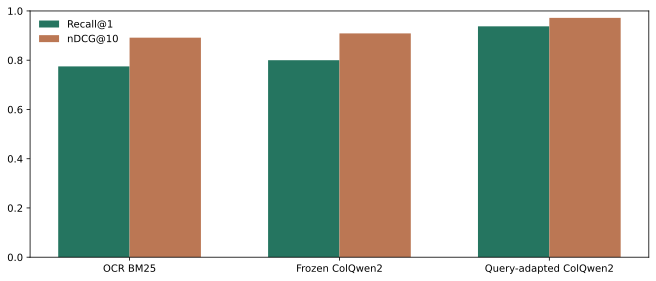

{
  "frozen": {
    "id": "SF-526862/date-and-service",
    "gold": "SF-526862",
    "text": "Find the GBP bill issued on 2025-12-21 that charges for Cable sleeve.",
    "kind": "date-and-service",
    "split": "novel",
    "family": "novel-06",
    "layout": "service",
    "arm": "frozen-colqwen2",
    "rank": 5,
    "top1": "SF-181336",
    "seconds": 0.09402435300125944
  },
  "adapted": {
    "id": "SF-526862/date-and-service",
    "gold": "SF-526862",
    "text": "Find the GBP bill issued on 2025-12-21 that charges for Cable sleeve.",
    "kind": "date-and-service",
    "split": "novel",
    "family": "novel-06",
    "layout": "service",
    "arm": "query-adapted-colqwen2",
    "rank": 6,
    "top1": "SF-576379",
    "seconds": 0.09398079300081008
  }
}
correct SF-526862
Ref SF-526862 / GBP
Service fee notice, 2025-12-21
Sample Supplier 7598
Unit 152.61 / 1 times / Cable sleeve
Unit 200.78 / 6 times / Packing insert
Unit 230.89 / 1 times / Cooling filter
Fee subtotal 1,588.18
Plus

In [8]:
pages, page_mask = pack_documents([test_index[key].to(device) for key in test_keys])
results = []


def add_result(query, arm, scores, started, encoding_seconds=0.0):
    rank, first = rank_of(scores, test_keys, query["gold"])
    seconds = encoding_seconds + perf_counter() - started
    results.append({**query, "arm": arm, "rank": rank, "top1": first, "seconds": seconds})


# Warm up each ranking path once with a train query outside the held-out results.
q0 = train_queries[0]["text"]
with torch.no_grad():
    v0 = encode_queries([q0], batch_size=1)[0].to(device)
    maxsim(F.normalize(v0, dim=-1), pages, page_mask).tolist()
    maxsim(adapter(v0), pages, page_mask).tolist()
bm25.get_scores(tokenize(q0))
torch.cuda.synchronize()

with torch.no_grad():
    for q in test_queries:
        start = perf_counter()
        lexical = bm25.get_scores(tokenize(q["text"])).tolist()
        add_result(q, "ocr-bm25", lexical, start)

        start = perf_counter()
        embedding = encode_queries([q["text"]], batch_size=1)[0].to(device)
        torch.cuda.synchronize()
        encode_seconds = perf_counter() - start

        start = perf_counter()
        baseline = maxsim(F.normalize(embedding, dim=-1), pages, page_mask).tolist()
        add_result(q, "frozen-colqwen2", baseline, start, encode_seconds)

        start = perf_counter()
        adapted = maxsim(adapter(embedding), pages, page_mask).tolist()
        add_result(q, "query-adapted-colqwen2", adapted, start, encode_seconds)


def summarize(rows):
    count = len(rows)
    return {
        "queries": count,
        "recall_at_1": sum(r["rank"] <= 1 for r in rows) / count,
        "recall_at_5": sum(r["rank"] <= 5 for r in rows) / count,
        "ndcg_at_10": sum(1 / math.log2(r["rank"] + 1) for r in rows if r["rank"] <= 10) / count,
        "median_query_ms": 1_000 * float(np.median([r["seconds"] for r in rows])),
        "p95_query_ms": 1_000 * float(np.percentile([r["seconds"] for r in rows], 95)),
    }


arms = ("ocr-bm25", "frozen-colqwen2", "query-adapted-colqwen2")
scores = {}
for arm in arms:
    arm_rows = [r for r in results if r["arm"] == arm]
    assert {r["id"] for r in arm_rows} == {q["id"] for q in test_queries}
    scores[arm] = {"all": summarize(arm_rows)}
    for name in ("split", "layout", "kind"):
        values = sorted({r[name] for r in arm_rows})
        scores[arm][name] = {v: summarize([r for r in arm_rows if r[name] == v]) for v in values}

def paired_ndcg_delta(treatment, control):
    treated = {r["id"]: r for r in results if r["arm"] == treatment}
    controls = {r["id"]: r for r in results if r["arm"] == control}
    family_rows = defaultdict(list)

    def gain(rank):
        return 1 / math.log2(rank + 1) if rank <= 10 else 0.0

    for key, row in treated.items():
        family_rows[row["family"]].append(gain(row["rank"]) - gain(controls[key]["rank"]))
    grouped = [family_rows[f] for f in sorted(family_rows)]
    rng = np.random.default_rng(SEED)
    sums = np.asarray([sum(group) for group in grouped])
    counts = np.asarray([len(group) for group in grouped])
    picks = rng.integers(0, len(grouped), size=(2000, len(grouped)))
    boot = sums[picks].sum(axis=1) / counts[picks].sum(axis=1)
    return {"delta": float(sums.sum() / counts.sum()),
            "p025": float(np.percentile(boot, 2.5)), "p975": float(np.percentile(boot, 97.5)),
            "families": len(grouped)}


paired = {f"{a}_minus_{b}": paired_ndcg_delta(a, b) for a, b in (
    ("frozen-colqwen2", "ocr-bm25"), ("query-adapted-colqwen2", "frozen-colqwen2"),
)}

fixture_digest = sha256("".join(invoice_text(p) for p in train_pages + test_pages).encode()).hexdigest()
report = {
    "gpu": torch.cuda.get_device_name(), "cuda": torch.version.cuda, "profile": PROFILE, "limits": LIMITS,
    "model": MODEL_ID, "revision": REVISION, "seed": SEED, "fixture_text_sha256": fixture_digest,
    "training_pages": sorted(train_by_key), "evaluation_candidates": test_keys,
    "peak_allocated_bytes": torch.cuda.max_memory_allocated(), "training_seconds": training_seconds,
    "ocr_index_seconds": ocr_index_time, "visual_index_seconds": vision_index_time,
    "ocr_index_bytes": (OUT / "ocr-index.json").stat().st_size,
    "visual_index_bytes": (OUT / "colqwen-index.pt").stat().st_size,
    "tesseract": str(pytesseract.get_tesseract_version()),
    "packages": {p: importlib.metadata.version(p) for p in ("torch", "transformers", "rank-bm25", "pytesseract")},
    "scores": scores, "paired_ndcg_at_10": paired, "preflight": profile_evidence,
}
(OUT / "report.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
(OUT / "ranks.jsonl").write_text("".join(json.dumps(r) + "\n" for r in results), encoding="utf-8")
(OUT / "train.jsonl").write_text("".join(json.dumps(r) + "\n" for r in history), encoding="utf-8")
print(json.dumps({"all": {a: s["all"] for a, s in scores.items()}, "paired_ndcg_at_10": paired}, indent=2))


fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
x = np.arange(len(arms))
ax.bar(x - 0.17, [scores[a]["all"]["recall_at_1"] for a in arms], 0.34, color="#257560", label="Recall@1")
ax.bar(x + 0.17, [scores[a]["all"]["ndcg_at_10"] for a in arms], 0.34, color="#bb7754", label="nDCG@10")
ax.set_xticks(x, ["OCR BM25", "Frozen ColQwen2", "Query-adapted ColQwen2"])
ax.set_ylim(0, 1)
ax.legend(frameon=False)
fig.savefig(OUT / "retrieval-quality.svg")
plt.show()

frozen = {r["id"]: r for r in results if r["arm"] == "frozen-colqwen2"}
adapted = {r["id"]: r for r in results if r["arm"] == "query-adapted-colqwen2"}
case = max(adapted, key=lambda key: adapted[key]["rank"] - frozen[key]["rank"])
print(json.dumps({"frozen": frozen[case], "adapted": adapted[case]}, indent=2))
for name, key in (("correct", adapted[case]["gold"]), ("adapter-top", adapted[case]["top1"])):
    invoice_image(test_by_key[key]).save(OUT / f"case-{name}.png")
    print(name, key)
    print(invoice_text(test_by_key[key]))
    print("OCR:", ocr_text[key])

## Read the result

Resample held-out supplier families, retaining all their paired queries, to
summarize uncertainty in each overall nDCG difference. Check whether any
aggregate gain survives on the unseen layouts. Add the
cost of storing visual token vectors and editing the retrieval query path to
the decision. The fixture is a small, generated corpus with a single positive
page per query. The page renderer, OCR language, layouts and candidate
density determine how far this result transfers.

[ColPali and ViDoRe](https://arxiv.org/abs/2407.01449) ·
[ColQwen2 checkpoint](https://huggingface.co/vidore/colqwen2-v1.0-hf) ·
[Tesseract OCR](https://github.com/tesseract-ocr/tesseract) ·
[Course lesson](https://docs.recohut.com/courses/advanced-llm-fine-tuning/3-adapt-models/09-tune-visual-retrieval)